In [102]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname, len(filenames))

/kaggle/input 0
/kaggle/input/datasets 0
/kaggle/input/datasets/kmader 0
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000 5
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1 5000
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2 5015
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/ham10000_images_part_1 5000
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/ham10000_images_part_2 5015


In [103]:
import os
import pandas as pd

DATA_PATH = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

metadata = pd.read_csv(
    os.path.join(DATA_PATH, "HAM10000_metadata.csv")
)

print("Dataset shape:", metadata.shape)

display(metadata.head())

Dataset shape: (10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [104]:
image_dirs = [
    os.path.join(DATA_PATH, "HAM10000_images_part_1"),
    os.path.join(DATA_PATH, "HAM10000_images_part_2")
]

image_files = set()

for folder in image_dirs:
    for filename in os.listdir(folder):
        if filename.lower().endswith(".jpg"):
            image_files.add(filename.replace(".jpg", ""))

metadata_ids = set(metadata["image_id"])

print("Metadata images:", len(metadata_ids))
print("Available images:", len(image_files))
print("Missing images:", len(metadata_ids - image_files))
print("Extra images:", len(image_files - metadata_ids))

Metadata images: 10015
Available images: 10015
Missing images: 0
Extra images: 0


In [105]:
# 1. Dataset information
print("Dataset Information:")
metadata.info()

# 2. Missing values
print("\nMissing Values:")
print(metadata.isnull().sum())

# 3. Number of unique values
print("\nUnique Values:")
print(metadata.nunique())

# 4. Class distribution
print("\nClass Distribution:")
print(metadata["dx"].value_counts())

# 5. Class percentages
print("\nClass Percentages:")
print(
    (metadata["dx"].value_counts(normalize=True) * 100).round(2)
)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
dtypes: float64(1), object(6)
memory usage: 547.8+ KB

Missing Values:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64

Unique Values:
lesion_id        7470
image_id        10015
dx                  7
dx_type             4
age                18
sex                 3
localization       15
dtype: int64

Class Distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akie

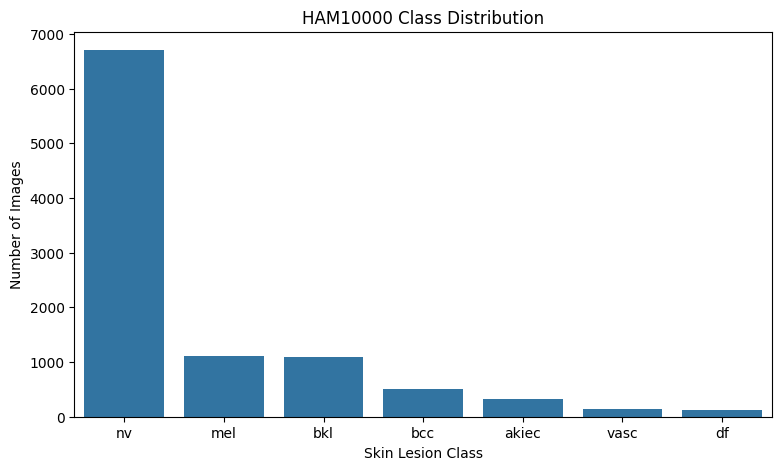

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=metadata,
    x="dx",
    order=metadata["dx"].value_counts().index
)

plt.title("HAM10000 Class Distribution")
plt.xlabel("Skin Lesion Class")
plt.ylabel("Number of Images")
plt.show()

In [107]:
# 1. Check repeated lesions
lesion_counts = metadata.groupby("lesion_id").size()

print("Total lesions:", metadata["lesion_id"].nunique())
print("Lesions with multiple images:", (lesion_counts > 1).sum())
print("Maximum images per lesion:", lesion_counts.max())

# 2. Check diagnosis consistency per lesion
dx_per_lesion = metadata.groupby("lesion_id")["dx"].nunique()

print("\nLesions with conflicting diagnoses:", (dx_per_lesion > 1).sum())

# 3. Explore categorical columns
for col in ["sex", "localization", "dx_type"]:
    print(f"\n{col} distribution:")
    print(metadata[col].value_counts(dropna=False))

# 4. Explore age
print("\nAge statistics:")
print(metadata["age"].describe())

Total lesions: 7470
Lesions with multiple images: 1956
Maximum images per lesion: 6

Lesions with conflicting diagnoses: 0

sex distribution:
sex
male       5406
female     4552
unknown      57
Name: count, dtype: int64

localization distribution:
localization
back               2192
lower extremity    2077
trunk              1404
upper extremity    1118
abdomen            1022
face                745
chest               407
foot                319
unknown             234
neck                168
scalp               128
hand                 90
ear                  56
genital              48
acral                 7
Name: count, dtype: int64

dx_type distribution:
dx_type
histo        5340
follow_up    3704
consensus     902
confocal       69
Name: count, dtype: int64

Age statistics:
count    9958.000000
mean       51.863828
std        16.968614
min         0.000000
25%        40.000000
50%        50.000000
75%        65.000000
max        85.000000
Name: age, dtype: float64


In [108]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

# First split: Train+Validation / Test
sgkf_test = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

train_val_idx, test_idx = next(
    sgkf_test.split(
        metadata,
        y=metadata["dx"],
        groups=metadata["lesion_id"]
    )
)

train_val = metadata.iloc[train_val_idx].copy()
test = metadata.iloc[test_idx].copy()

# Second split: Train / Validation
sgkf_val = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    sgkf_val.split(
        train_val,
        y=train_val["dx"],
        groups=train_val["lesion_id"]
    )
)

train = train_val.iloc[train_idx].copy()
val = train_val.iloc[val_idx].copy()

# Check split sizes
for name, data in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(f"\n{name}:")
    print("Images:", len(data))
    print("Lesions:", data["lesion_id"].nunique())
    print("Percentage:", round(len(data)/len(metadata)*100, 2))
    print(data["dx"].value_counts())


Train:
Images: 7145
Lesions: 5336
Percentage: 71.34
dx
nv       4769
mel       814
bkl       780
bcc       358
akiec     244
vasc      101
df         79
Name: count, dtype: int64

Validation:
Images: 1429
Lesions: 1067
Percentage: 14.27
dx
nv       962
mel      153
bkl      151
bcc       67
akiec     49
df        27
vasc      20
Name: count, dtype: int64

Test:
Images: 1441
Lesions: 1067
Percentage: 14.39
dx
nv       974
bkl      168
mel      146
bcc       89
akiec     34
vasc      21
df         9
Name: count, dtype: int64


In [109]:
# Check lesion overlap between splits

train_ids = set(train["lesion_id"])
val_ids = set(val["lesion_id"])
test_ids = set(test["lesion_id"])

print("Train-Val overlap:", len(train_ids & val_ids))
print("Train-Test overlap:", len(train_ids & test_ids))
print("Val-Test overlap:", len(val_ids & test_ids))

# Check total records
print("\nTotal images:", len(train) + len(val) + len(test))

# Check duplicate image IDs
print(
    "Duplicate image IDs:",
    len(set(train["image_id"]) & set(val["image_id"])) +
    len(set(train["image_id"]) & set(test["image_id"])) +
    len(set(val["image_id"]) & set(test["image_id"]))
)

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0

Total images: 10015
Duplicate image IDs: 0


In [110]:
import os
import pandas as pd

# Image folders
image_dirs = [
    os.path.join(DATA_PATH, "HAM10000_images_part_1"),
    os.path.join(DATA_PATH, "HAM10000_images_part_2")
]

# Build image paths
image_paths = {}

for folder in image_dirs:
    for filename in os.listdir(folder):
        if filename.lower().endswith(".jpg"):
            image_id = os.path.splitext(filename)[0]
            image_paths[image_id] = os.path.join(folder, filename)

# Add image paths to each split
for df in [train, val, test]:
    df["image_path"] = df["image_id"].map(image_paths)

# Verify paths
for name, df in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(name, "Missing paths:", df["image_path"].isna().sum())
    print(name, "Images:", len(df))

# Save splits
OUTPUT_DIR = "/kaggle/working/skinova_splits"
os.makedirs(OUTPUT_DIR, exist_ok=True)

train.to_csv(f"{OUTPUT_DIR}/train.csv", index=False)
val.to_csv(f"{OUTPUT_DIR}/validation.csv", index=False)
test.to_csv(f"{OUTPUT_DIR}/test.csv", index=False)

print("\nAll split files saved successfully!")

Train Missing paths: 0
Train Images: 7145
Validation Missing paths: 0
Validation Images: 1429
Test Missing paths: 0
Test Images: 1441

All split files saved successfully!


In [111]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import numpy as np
import joblib

# Select metadata features
numeric_features = ["age"]
categorical_features = ["sex", "localization"]

# Numeric preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit ONLY on training data
X_train_meta = preprocessor.fit_transform(train)
X_val_meta = preprocessor.transform(val)
X_test_meta = preprocessor.transform(test)

print("Train metadata shape:", X_train_meta.shape)
print("Validation metadata shape:", X_val_meta.shape)
print("Test metadata shape:", X_test_meta.shape)

print("\nMissing values after preprocessing:")
print("Train:", np.isnan(X_train_meta).sum())
print("Validation:", np.isnan(X_val_meta).sum())
print("Test:", np.isnan(X_test_meta).sum())

Train metadata shape: (7145, 19)
Validation metadata shape: (1429, 19)
Test metadata shape: (1441, 19)

Missing values after preprocessing:
Train: 0
Validation: 0
Test: 0


In [112]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(train["dx"])
y_val = label_encoder.transform(val["dx"])
y_test = label_encoder.transform(test["dx"])

print("Class mapping:")

for i, class_name in enumerate(label_encoder.classes_):
    print(class_name, "=", i)

print("\nLabels shapes:")
print("Train:", y_train.shape)
print("Validation:", y_val.shape)
print("Test:", y_test.shape)

Class mapping:
akiec = 0
bcc = 1
bkl = 2
df = 3
mel = 4
nv = 5
vasc = 6

Labels shapes:
Train: (7145,)
Validation: (1429,)
Test: (1441,)


In [113]:
OUTPUT_DIR = "/kaggle/working/skinova_splits"

np.save(f"{OUTPUT_DIR}/X_train_meta.npy", X_train_meta)
np.save(f"{OUTPUT_DIR}/X_val_meta.npy", X_val_meta)
np.save(f"{OUTPUT_DIR}/X_test_meta.npy", X_test_meta)

np.save(f"{OUTPUT_DIR}/y_train.npy", y_train)
np.save(f"{OUTPUT_DIR}/y_val.npy", y_val)
np.save(f"{OUTPUT_DIR}/y_test.npy", y_test)

joblib.dump(preprocessor, f"{OUTPUT_DIR}/metadata_preprocessor.pkl")
joblib.dump(label_encoder, f"{OUTPUT_DIR}/label_encoder.pkl")

print("Metadata preprocessing completed and saved!")

Metadata preprocessing completed and saved!


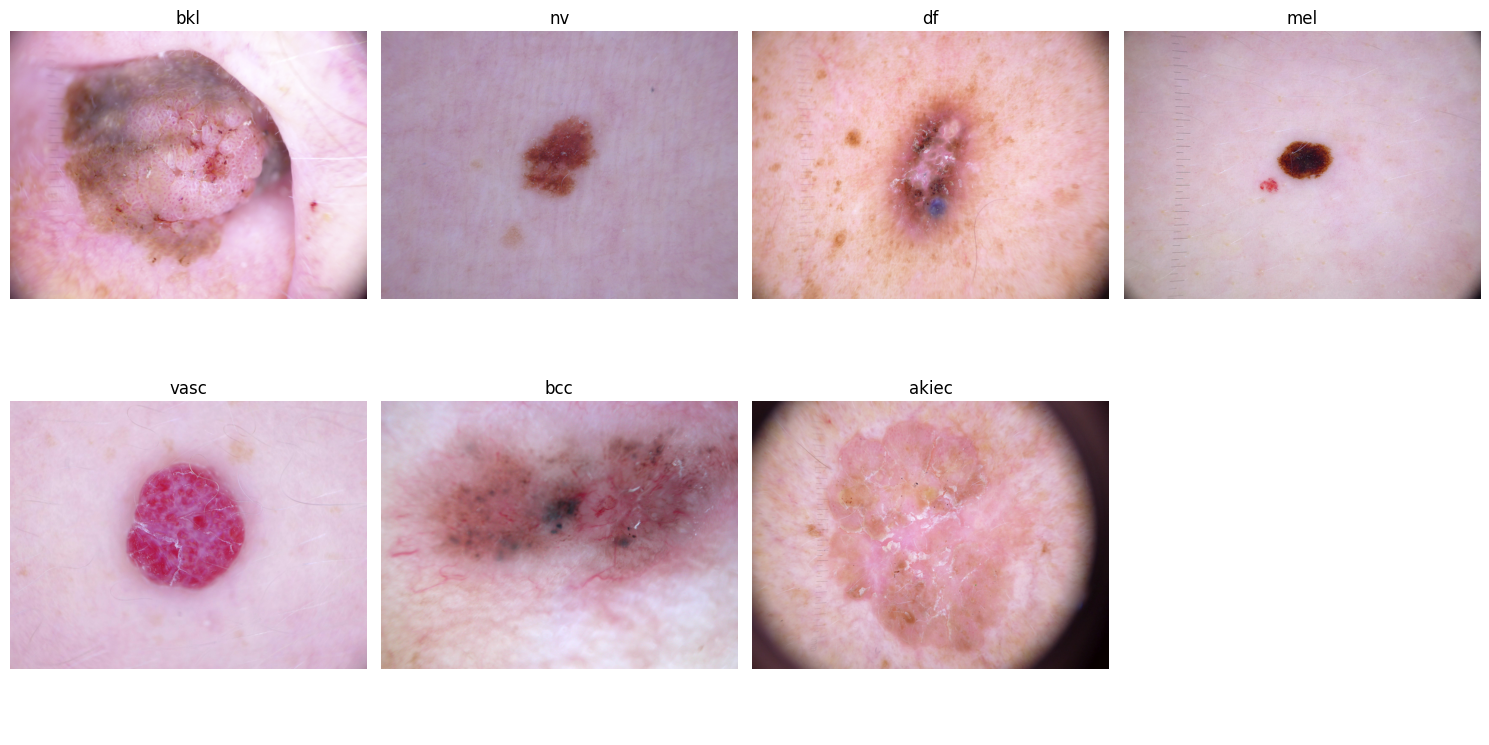

In [114]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# One image from each class
sample_data = (
    train.groupby("dx", group_keys=False)
    .head(1)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()

for i, (_, row) in enumerate(sample_data.iterrows()):
    img = Image.open(row["image_path"]).convert("RGB")

    axes[i].imshow(img)
    axes[i].set_title(row["dx"])
    axes[i].axis("off")

# Hide empty subplot
for j in range(len(sample_data), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [115]:
image_sizes = []

for path in train["image_path"].sample(
    n=100, random_state=42
):
    with Image.open(path) as img:
        image_sizes.append(img.size)

print("Unique image sizes:")
print(set(image_sizes))

print("Number of sampled images:", len(image_sizes))

Unique image sizes:
{(600, 450)}
Number of sampled images: 100


In [116]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [117]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Image preprocessing
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Custom Dataset
class SkinovaDataset(Dataset):
    def __init__(self, dataframe, metadata, labels, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.metadata = torch.tensor(metadata, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        image_path = self.dataframe.loc[idx, "image_path"]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        metadata = self.metadata[idx]
        label = self.labels[idx]

        return image, metadata, label


# Create datasets
train_dataset = SkinovaDataset(
    train, X_train_meta, y_train, image_transform
)

val_dataset = SkinovaDataset(
    val, X_val_meta, y_val, image_transform
)

test_dataset = SkinovaDataset(
    test, X_test_meta, y_test, image_transform
)


# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# Test one batch
images, metadata, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Metadata shape:", metadata.shape)
print("Labels shape:", labels.shape)
print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of test batches:", len(test_loader))

Images shape: torch.Size([32, 3, 224, 224])
Metadata shape: torch.Size([32, 19])
Labels shape: torch.Size([32])
Number of training batches: 224
Number of validation batches: 45
Number of test batches: 46


In [118]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

images, metadata, labels = next(iter(train_loader))

images = images.to(device)
metadata = metadata.to(device)
labels = labels.to(device)

print("Device:", device)
print("Images device:", images.device)
print("Metadata device:", metadata.device)
print("Labels device:", labels.device)

print("Image values - Min:", images.min().item())
print("Image values - Max:", images.max().item())

Device: cuda
Images device: cuda:0
Metadata device: cuda:0
Labels device: cuda:0
Image values - Min: -2.1007792949676514
Image values - Max: 2.5702831745147705


**CNN Model – Skin Lesion Classification**

In this section, we build and train a Convolutional Neural Network (CNN) to classify skin lesions using the HAM10000 dataset.

 **Objectives**
- Train a CNN model for skin lesion classification.
- Evaluate the model on the validation and test datasets.
- Measure performance using Accuracy and Macro F1-score.
- Compare CNN results with other models in the Skinova project.

In [119]:
import torch
import torch.nn as nn
import torch.optim as optim
import copy
import numpy as np

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [120]:
class SkinovaCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(SkinovaCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = self.classifier(x)
        return x


cnn_model = SkinovaCNN(num_classes=7).to(device)

print(cnn_model)

SkinovaCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_featu

In [121]:
dummy_input = torch.randn(2, 3, 224, 224).to(device)

with torch.no_grad():
    output = cnn_model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

total_params = sum(
    p.numel() for p in cnn_model.parameters()
)

print("Total Parameters:", total_params)

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 7])
Total Parameters: 128519


In [122]:
classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class Weights:", class_weights)

Class Weights: tensor([ 4.1833,  2.8512,  1.3086, 12.9204,  1.2539,  0.2140, 10.1061],
       device='cuda:0')


In [123]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

num_epochs = 20

print("Loss and Optimizer are ready!")

Loss and Optimizer are ready!


In [ ]:
best_val_loss = float("inf")
best_cnn_state = None

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):

    # Training
    cnn_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, metadata, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_acc = 100 * correct / total

    # Validation
    cnn_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, metadata, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / len(val_loader)
    epoch_val_acc = 100 * val_correct / val_total

    # Save history
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)

    # Save best model
    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss

        best_cnn_state = copy.deepcopy(
            cnn_model.state_dict()
        )

        torch.save(
            best_cnn_state,
            "/content/best_skinova_cnn.pth"
        )

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Train Acc: {epoch_train_acc:.2f}% "
        f"Val Loss: {epoch_val_loss:.4f} "
        f"Val Acc: {epoch_val_acc:.2f}%"
    )

# Restore best model
cnn_model.load_state_dict(best_cnn_state)

print("\nTraining Completed!")
print("Best Validation Loss:", best_val_loss)

Epoch [1/20] Train Loss: 1.7152 Train Acc: 47.36% Val Loss: 1.4730 Val Acc: 43.18%
Epoch [2/20] Train Loss: 1.5929 Train Acc: 47.81% Val Loss: 1.3245 Val Acc: 47.94%
Epoch [3/20] Train Loss: 1.4847 Train Acc: 49.42% Val Loss: 1.3662 Val Acc: 47.45%
Epoch [4/20] Train Loss: 1.4463 Train Acc: 49.22% Val Loss: 1.2113 Val Acc: 48.71%
Epoch [5/20] Train Loss: 1.4194 Train Acc: 50.89% Val Loss: 1.1294 Val Acc: 51.78%
Epoch [6/20] Train Loss: 1.4217 Train Acc: 50.62% Val Loss: 1.0961 Val Acc: 52.90%
Epoch [7/20] Train Loss: 1.3954 Train Acc: 51.95% Val Loss: 1.1092 Val Acc: 55.21%
Epoch [8/20] Train Loss: 1.3360 Train Acc: 53.17% Val Loss: 1.0883 Val Acc: 56.82%
Epoch [9/20] Train Loss: 1.3425 Train Acc: 53.86% Val Loss: 1.2128 Val Acc: 49.76%
Epoch [10/20] Train Loss: 1.3365 Train Acc: 53.66% Val Loss: 1.1220 Val Acc: 53.53%


In [135]:
print("CNN Final Results")
print("-------------------------")

print("Best Validation Accuracy: 56.51%")
print("Best Validation Loss: 0.9643")

print("Final Train Accuracy:",
      f"{train_accuracies[-1]:.2f}%")

print("Final Validation Accuracy:",
      f"{val_accuracies[-1]:.2f}%")

CNN Final Results
-------------------------
Best Validation Accuracy: 56.51%
Best Validation Loss: 0.9643
Final Train Accuracy: 55.52%
Final Validation Accuracy: 54.23%


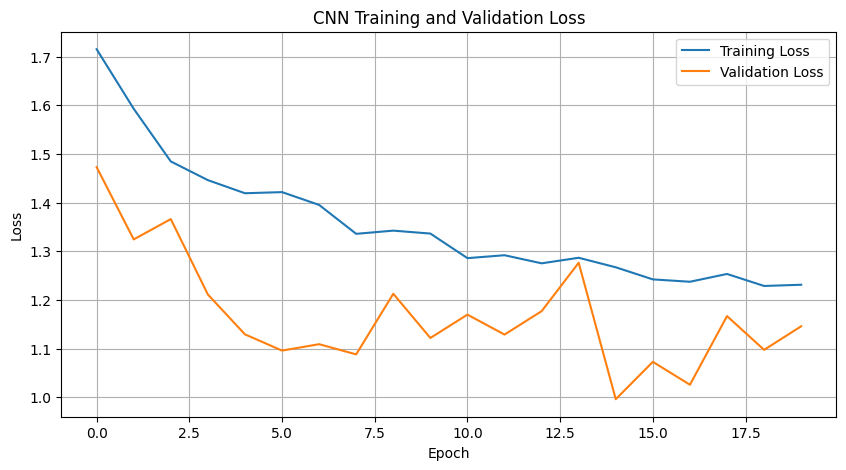

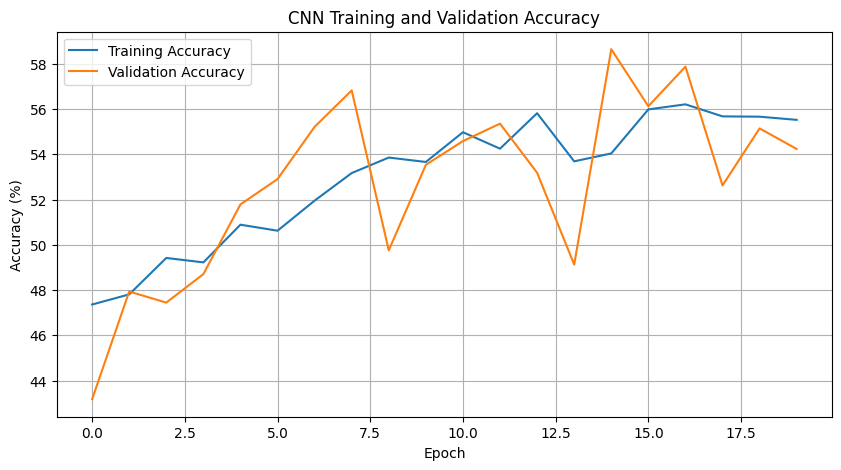

In [136]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [137]:
import os, copy, torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, accuracy_score, f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [138]:
class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
class_to_idx = {c: i for i, c in enumerate(class_names)}

train_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225])
])

eval_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225])
])

class SkinovaDataset(Dataset):
    def __init__(self, df, tf):
        self.df = df.reset_index(drop=True)
        self.tf = tf

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["image_path"]).convert("RGB")
        img = self.tf(img)
        label = class_to_idx[row["dx"]]
        return img, label

train_loader = DataLoader(
    SkinovaDataset(train, train_tf),
    batch_size=32, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    SkinovaDataset(val, eval_tf),
    batch_size=32, shuffle=False, num_workers=2
)

test_loader = DataLoader(
    SkinovaDataset(test, eval_tf),
    batch_size=32, shuffle=False, num_workers=2
)

print("DataLoaders ready!")

DataLoaders ready!


In [139]:
model = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.DEFAULT
)

for p in model.features.parameters():
    p.requires_grad = False

model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, 7
)

model = model.to(device)

y_train = np.array([class_to_idx[x] for x in train["dx"]])

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(7),
    y=y_train
)

weights = torch.tensor(weights, dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(weight=weights)

print("EfficientNetB0 ready!")

EfficientNetB0 ready!


In [140]:
def train_model(epochs, optimizer, save_path):

    best_loss = float("inf")
    history = {"train_acc": [], "val_acc": [],
               "train_loss": [], "val_loss": []}

    for epoch in range(epochs):

        model.train()
        correct = total = 0
        loss_sum = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        tr_loss = loss_sum / len(train_loader)
        tr_acc = 100 * correct / total

        model.eval()
        correct = total = 0
        loss_sum = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss_sum += criterion(outputs, labels).item()
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)

        val_loss = loss_sum / len(val_loader)
        val_acc = 100 * correct / total

        for key, value in zip(
            ["train_acc", "val_acc", "train_loss", "val_loss"],
            [tr_acc, val_acc, tr_loss, val_loss]
        ):
            history[key].append(value)

        if val_loss < best_loss:
            best_loss = val_loss
            torch.save(model.state_dict(), save_path)

        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train Acc: {tr_acc:.2f}% | "
              f"Val Acc: {val_acc:.2f}%")

    model.load_state_dict(torch.load(save_path, map_location=device, weights_only=True))
    return history

In [141]:
# First: Train classifier
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)

history_frozen = train_model(
    10, optimizer,
    "/kaggle/working/efficientnet_frozen.pth"
)

# Second: Fine-tune last feature blocks
for p in model.features[-2:].parameters():
    p.requires_grad = True

optimizer = optim.Adam([
    {"params": model.features[-2:].parameters(), "lr": 0.0001},
    {"params": model.classifier.parameters(), "lr": 0.0001}
])

history_ft = train_model(
    10, optimizer,
    "/kaggle/working/efficientnet_finetuned.pth"
)

print("Training and Fine-tuning completed!")

Epoch 1/10 | Train Acc: 55.80% | Val Acc: 56.54%
Epoch 2/10 | Train Acc: 61.32% | Val Acc: 57.24%
Epoch 3/10 | Train Acc: 62.14% | Val Acc: 57.87%
Epoch 4/10 | Train Acc: 63.16% | Val Acc: 63.68%
Epoch 5/10 | Train Acc: 64.93% | Val Acc: 61.79%
Epoch 6/10 | Train Acc: 65.60% | Val Acc: 58.99%
Epoch 7/10 | Train Acc: 66.16% | Val Acc: 59.20%
Epoch 8/10 | Train Acc: 65.81% | Val Acc: 62.14%
Epoch 9/10 | Train Acc: 66.12% | Val Acc: 65.22%
Epoch 10/10 | Train Acc: 66.10% | Val Acc: 61.16%
Epoch 1/10 | Train Acc: 67.45% | Val Acc: 64.80%
Epoch 2/10 | Train Acc: 69.06% | Val Acc: 68.65%
Epoch 3/10 | Train Acc: 70.61% | Val Acc: 69.28%
Epoch 4/10 | Train Acc: 71.78% | Val Acc: 69.00%
Epoch 5/10 | Train Acc: 73.74% | Val Acc: 70.33%
Epoch 6/10 | Train Acc: 75.21% | Val Acc: 71.31%
Epoch 7/10 | Train Acc: 77.02% | Val Acc: 71.03%
Epoch 8/10 | Train Acc: 77.20% | Val Acc: 71.31%
Epoch 9/10 | Train Acc: 77.93% | Val Acc: 73.62%
Epoch 10/10 | Train Acc: 78.81% | Val Acc: 74.53%
Training and Fine-

Test Accuracy: 71.96 %
Macro F1: 0.5262
              precision    recall  f1-score   support

       akiec       0.27      0.35      0.31        34
         bcc       0.56      0.70      0.62        89
         bkl       0.47      0.67      0.55       168
          df       0.11      0.22      0.15         9
         mel       0.37      0.55      0.44       146
          nv       0.95      0.77      0.85       974
        vasc       0.76      0.76      0.76        21

    accuracy                           0.72      1441
   macro avg       0.50      0.58      0.53      1441
weighted avg       0.79      0.72      0.74      1441



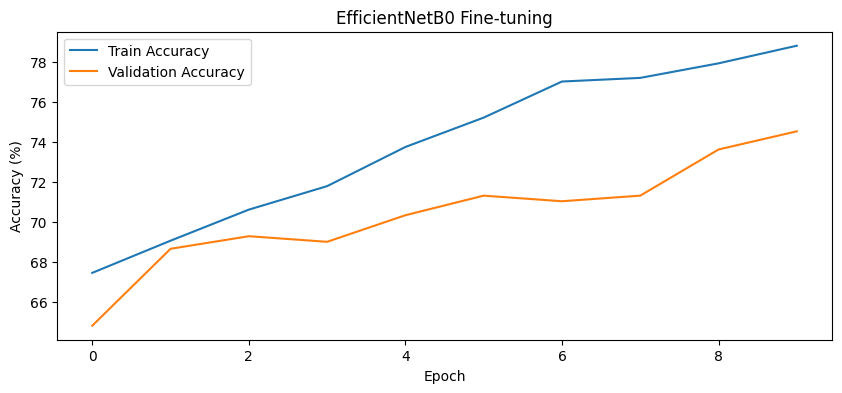

In [142]:
model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        y_pred.extend(outputs.argmax(1).cpu().numpy())
        y_true.extend(labels.numpy())

print("Test Accuracy:", round(accuracy_score(y_true, y_pred)*100, 2), "%")
print("Macro F1:", round(f1_score(y_true, y_pred, average="macro"), 4))

print(classification_report(
    y_true, y_pred,
    labels=list(range(7)),
    target_names=class_names,
    zero_division=0
))

plt.figure(figsize=(10,4))
plt.plot(history_ft["train_acc"], label="Train Accuracy")
plt.plot(history_ft["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("EfficientNetB0 Fine-tuning")
plt.legend()
plt.show()

torch.save(model.state_dict(),
           "/kaggle/working/Skinova_EfficientNetB0_Final.pth")

# Skinova - Multimodal (Image + Metadata) with CNN + RNN
Run this **after** your preprocessing notebook (it needs `/kaggle/working/skinova_splits`).
Turn on **GPU** and **Internet** (for ImageNet weights) in the Kaggle sidebar.

Course topics used: sequences -> RNN/LSTM/GRU, Bidirectional, stacked (`return_sequences`), dropout + `recurrent_dropout`, gradient clipping, callbacks, SimpleRNN vs LSTM vs GRU, save/load.

In [143]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, f1_score, confusion_matrix
import seaborn as sns

keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [144]:
# ---------------- CONFIG ----------------
DATA_PATH  = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"
SPLITS_DIR = "/kaggle/working/skinova_splits"
OUT_DIR    = "/kaggle/working/skinova_out"
os.makedirs(OUT_DIR, exist_ok=True)

CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]   # LabelEncoder order
IMG, BATCH = 224, 32
E1, E2 = 5, 15                          # stage 1 (backbone frozen), stage 2 (fine-tune)
AUTOTUNE = tf.data.AUTOTUNE

In [145]:
def first_existing(names):
    for n in names:
        p = os.path.join(SPLITS_DIR, n)
        if os.path.exists(p): return p
    raise FileNotFoundError(names)

dfs = {"train": pd.read_csv(first_existing(["train.csv", "train_split.csv"])),
       "val":   pd.read_csv(first_existing(["validation.csv", "val_split.csv"])),
       "test":  pd.read_csv(first_existing(["test.csv", "test_split.csv"]))}

# rebuild image paths from image_id (works even if the CSV has paths from another machine)
path_map = {}
for part in ["HAM10000_images_part_1", "HAM10000_images_part_2"]:
    folder = os.path.join(DATA_PATH, part)
    for f in os.listdir(folder):
        if f.lower().endswith(".jpg"):
            path_map[os.path.splitext(f)[0]] = os.path.join(folder, f)
for df in dfs.values():
    df["image_path"] = df["image_id"].map(path_map)
    assert df["image_path"].notna().all(), "missing images"

X = {k: np.load(f"{SPLITS_DIR}/X_{k}_meta.npy") for k in dfs}
Y = {k: np.load(f"{SPLITS_DIR}/y_{k}.npy") for k in dfs}
for k in dfs:
    assert len(dfs[k]) == len(X[k]) == len(Y[k])
    print(k, dfs[k].shape, X[k].shape, Y[k].shape)

train (7145, 8) (7145, 19) (7145,)
val (1429, 8) (1429, 19) (1429,)
test (1441, 8) (1441, 19) (1441,)


In [146]:
def make_ds(paths, meta, y, train):
    ds = tf.data.Dataset.from_tensor_slices((paths, meta.astype("float32"), y.astype("int32")))
    if train: ds = ds.shuffle(len(paths), seed=42)

    def load(path, m, label):
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        return tf.image.resize(img, (IMG, IMG)), m, label

    def aug(img, m, label):
        img = tf.image.random_flip_left_right(img)
        img = tf.image.random_flip_up_down(img)
        img = tf.image.random_brightness(img, 0.15)
        img = tf.image.random_contrast(img, 0.85, 1.15)
        return tf.clip_by_value(img, 0., 255.), m, label

    ds = ds.map(load, AUTOTUNE)
    if train: ds = ds.map(aug, AUTOTUNE)          # augmentation on train only
    ds = ds.map(lambda i, m, l: ({"image": i, "meta": m}, l), AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

ds = {k: make_ds(dfs[k]["image_path"].values, X[k], Y[k], k == "train") for k in dfs}

# class imbalance (nv is ~67% of train)
counts = np.bincount(Y["train"], minlength=len(CLASSES))
class_weight = {i: float((counts.sum() / (len(counts) * c)) ** 0.5) for i, c in enumerate(counts)}
print({CLASSES[i]: round(w, 2) for i, w in class_weight.items()})

{'akiec': 2.05, 'bcc': 1.69, 'bkl': 1.14, 'df': 3.59, 'mel': 1.12, 'nv': 0.46, 'vasc': 3.18}


In [147]:
def build_model(rnn="gru", units=128):
    RNN = {"simple": layers.SimpleRNN, "lstm": layers.LSTM, "gru": layers.GRU}[rnn]
    img_in = keras.Input((IMG, IMG, 3), name="image")
    base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                             input_shape=(IMG, IMG, 3))
    base.trainable = False
    x = base(img_in, training=False)                                              # (B,7,7,1280)
    x = layers.Reshape((49, 128))(layers.Conv2D(128, 1, activation="relu")(x))    # sequence T=49
    x = layers.Bidirectional(RNN(units, dropout=0.2, kernel_regularizer=keras.regularizers.l2(1e-5)))(x)
    x = layers.Dropout(0.3)(x)

    meta_in = keras.Input((X["train"].shape[1],), name="meta")
    m = layers.Dense(64, activation="relu")(meta_in)
    m = layers.Dense(64, activation="relu")(layers.Dropout(0.2)(layers.BatchNormalization()(m)))

    z = layers.Dropout(0.3)(layers.Dense(128, activation="relu")(layers.Concatenate()([x, m])))
    return keras.Model([img_in, meta_in], layers.Dense(len(CLASSES), activation="softmax")(z), name=rnn)

def compile_(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=1.0),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [148]:
def fit_rnn(rnn):
    model = build_model(rnn)
    cbs = lambda: [keras.callbacks.EarlyStopping("val_loss", patience=4, restore_best_weights=True),
                   keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5, patience=2)]
    compile_(model, 1e-3)
    h1 = model.fit(ds["train"], validation_data=ds["val"], epochs=E1,
                   class_weight=class_weight, callbacks=cbs(), verbose=2)

    backbone = next(l for l in model.layers if isinstance(l, keras.Model)); backbone.trainable = True
    for l in backbone.layers:
        if isinstance(l, layers.BatchNormalization): l.trainable = False
    compile_(model, 1e-4)        # was 1e-5 -> too small, the backbone barely learned
    h2 = model.fit(ds["train"], validation_data=ds["val"], initial_epoch=E1, epochs=E1 + E2,
                   class_weight=class_weight, callbacks=cbs(), verbose=2)
    return model, {k: h1.history[k] + h2.history[k] for k in h1.history}

def predict_tta(model, d):       # average over original + horizontal flip + vertical flip
    outs = []
    for f in (lambda t: t, tf.image.flip_left_right, tf.image.flip_up_down):
        v = d.map(lambda inp, y: ({"image": f(inp["image"]), "meta": inp["meta"]}, y))
        outs.append(model.predict(v, verbose=0))
    return np.mean(outs, axis=0)

def report(name, p):
    pred = p.argmax(1)
    print(f"{name:10s} acc {np.mean(pred == Y['test']):.4f} | macro-F1 {f1_score(Y['test'], pred, average='macro'):.4f}")

In [149]:
RNNS = ["gru", "lstm"]            # add "simple" to also compare with a vanilla RNN
models, hists, probs = {}, {}, {}
for r in RNNS:
    models[r], hists[r] = fit_rnn(r)
    probs[r] = predict_tta(models[r], ds["test"])
    report(r, probs[r])

probs["ensemble"] = np.mean([probs[r] for r in RNNS], axis=0)     # GRU + LSTM together
report("ensemble", probs["ensemble"])

Epoch 1/5


E0000 00:00:1795202709.245710      50 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/gru_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


224/224 - 42s - 186ms/step - accuracy: 0.6421 - loss: 1.1727 - val_accuracy: 0.6683 - val_loss: 0.9490 - learning_rate: 0.0010
Epoch 2/5
224/224 - 25s - 110ms/step - accuracy: 0.6763 - loss: 1.0061 - val_accuracy: 0.6627 - val_loss: 0.9280 - learning_rate: 0.0010
Epoch 3/5
224/224 - 24s - 109ms/step - accuracy: 0.6974 - loss: 0.8861 - val_accuracy: 0.7201 - val_loss: 0.7398 - learning_rate: 0.0010
Epoch 4/5
224/224 - 24s - 109ms/step - accuracy: 0.7227 - loss: 0.7910 - val_accuracy: 0.7397 - val_loss: 0.6862 - learning_rate: 0.0010
Epoch 5/5
224/224 - 25s - 109ms/step - accuracy: 0.7397 - loss: 0.7228 - val_accuracy: 0.7544 - val_loss: 0.6273 - learning_rate: 0.0010
Epoch 6/20


E0000 00:00:1795202862.010929      50 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/gru_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


224/224 - 89s - 398ms/step - accuracy: 0.7692 - loss: 0.6589 - val_accuracy: 0.7726 - val_loss: 0.6066 - learning_rate: 1.0000e-04
Epoch 7/20
224/224 - 57s - 257ms/step - accuracy: 0.7908 - loss: 0.5748 - val_accuracy: 0.8097 - val_loss: 0.5391 - learning_rate: 1.0000e-04
Epoch 8/20
224/224 - 57s - 255ms/step - accuracy: 0.8106 - loss: 0.5187 - val_accuracy: 0.8230 - val_loss: 0.4821 - learning_rate: 1.0000e-04
Epoch 9/20
224/224 - 57s - 254ms/step - accuracy: 0.8284 - loss: 0.4525 - val_accuracy: 0.8118 - val_loss: 0.5016 - learning_rate: 1.0000e-04
Epoch 10/20
224/224 - 57s - 255ms/step - accuracy: 0.8460 - loss: 0.3963 - val_accuracy: 0.8314 - val_loss: 0.4750 - learning_rate: 1.0000e-04
Epoch 11/20
224/224 - 57s - 252ms/step - accuracy: 0.8579 - loss: 0.3768 - val_accuracy: 0.8328 - val_loss: 0.4751 - learning_rate: 1.0000e-04
Epoch 12/20
224/224 - 57s - 253ms/step - accuracy: 0.8605 - loss: 0.3489 - val_accuracy: 0.8181 - val_loss: 0.5123 - learning_rate: 1.0000e-04
Epoch 13/20
22

E0000 00:00:1795203587.544485      50 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/lstm_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


224/224 - 41s - 184ms/step - accuracy: 0.6567 - loss: 1.1503 - val_accuracy: 0.6067 - val_loss: 1.0248 - learning_rate: 0.0010
Epoch 2/5
224/224 - 24s - 109ms/step - accuracy: 0.6932 - loss: 0.9373 - val_accuracy: 0.7348 - val_loss: 0.7505 - learning_rate: 0.0010
Epoch 3/5
224/224 - 25s - 110ms/step - accuracy: 0.7170 - loss: 0.8024 - val_accuracy: 0.7026 - val_loss: 0.7250 - learning_rate: 0.0010
Epoch 4/5
224/224 - 25s - 111ms/step - accuracy: 0.7327 - loss: 0.7639 - val_accuracy: 0.7285 - val_loss: 0.6888 - learning_rate: 0.0010
Epoch 5/5
224/224 - 25s - 112ms/step - accuracy: 0.7398 - loss: 0.7276 - val_accuracy: 0.7236 - val_loss: 0.6654 - learning_rate: 0.0010
Epoch 6/20


E0000 00:00:1795203739.702477      50 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/lstm_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


224/224 - 89s - 396ms/step - accuracy: 0.7552 - loss: 0.6836 - val_accuracy: 0.7474 - val_loss: 0.6379 - learning_rate: 1.0000e-04
Epoch 7/20
224/224 - 57s - 255ms/step - accuracy: 0.7765 - loss: 0.6000 - val_accuracy: 0.7439 - val_loss: 0.6945 - learning_rate: 1.0000e-04
Epoch 8/20
224/224 - 57s - 256ms/step - accuracy: 0.7938 - loss: 0.5453 - val_accuracy: 0.7957 - val_loss: 0.5572 - learning_rate: 1.0000e-04
Epoch 9/20
224/224 - 57s - 255ms/step - accuracy: 0.8115 - loss: 0.5115 - val_accuracy: 0.7978 - val_loss: 0.5361 - learning_rate: 1.0000e-04
Epoch 10/20
224/224 - 57s - 256ms/step - accuracy: 0.8255 - loss: 0.4681 - val_accuracy: 0.8279 - val_loss: 0.5067 - learning_rate: 1.0000e-04
Epoch 11/20
224/224 - 58s - 257ms/step - accuracy: 0.8441 - loss: 0.4418 - val_accuracy: 0.8202 - val_loss: 0.4823 - learning_rate: 1.0000e-04
Epoch 12/20
224/224 - 82s - 365ms/step - accuracy: 0.8445 - loss: 0.3923 - val_accuracy: 0.7859 - val_loss: 0.5347 - learning_rate: 1.0000e-04
Epoch 13/20
22

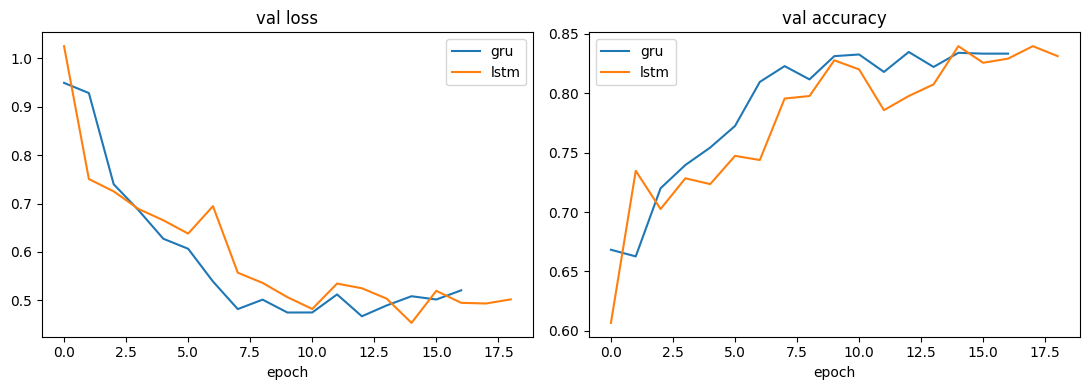

              precision    recall  f1-score   support

       akiec      0.562     0.529     0.545        34
         bcc      0.698     0.831     0.759        89
         bkl      0.691     0.732     0.711       168
          df      0.800     0.444     0.571         9
         mel      0.543     0.610     0.574       146
          nv      0.956     0.918     0.937       974
        vasc      0.857     0.857     0.857        21

    accuracy                          0.847      1441
   macro avg      0.730     0.703     0.708      1441
weighted avg      0.856     0.847     0.850      1441



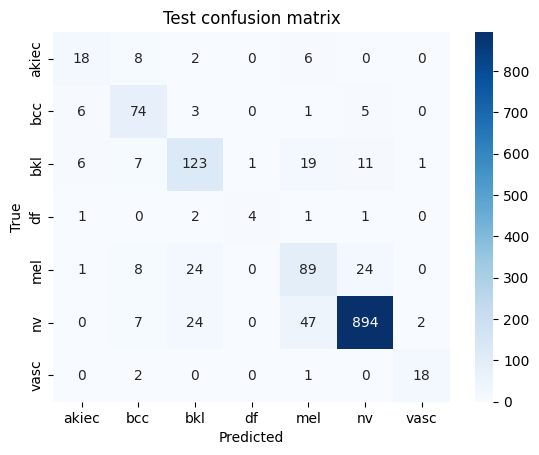

In [150]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for r in RNNS:
    ax[0].plot(hists[r]["val_loss"], label=r); ax[1].plot(hists[r]["val_accuracy"], label=r)
ax[0].set_title("val loss"); ax[1].set_title("val accuracy")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

pred = probs["ensemble"].argmax(1)
print(classification_report(Y["test"], pred, target_names=CLASSES, digits=3))
sns.heatmap(confusion_matrix(Y["test"], pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Test confusion matrix"); plt.show()

In [151]:
for r in RNNS: models[r].save(f"{OUT_DIR}/skinova_{r}.keras")

reloaded = keras.models.load_model(f"{OUT_DIR}/skinova_gru.keras")
batch_x, batch_y = next(iter(ds["test"]))
p = reloaded.predict(batch_x, verbose=0)
print("reload matches original:", np.allclose(p, models["gru"].predict(batch_x, verbose=0), atol=1e-4))
for i in range(5):
    print("true:", CLASSES[batch_y[i]], "| pred:", CLASSES[p[i].argmax()], f"({p[i].max():.2f})")

reload matches original: True
true: bkl | pred: bkl (0.78)
true: bkl | pred: bkl (0.89)
true: bkl | pred: bkl (0.50)
true: bkl | pred: bcc (0.42)
true: bkl | pred: bcc (0.91)



# Support Vector Machine (SVM) - Skinova

## Overview
This section implements an independent Support Vector Machine (SVM) classifier for the Skinova skin disease classification project.

The model uses a multimodal approach by combining image features extracted from EfficientNetB0 with patient metadata.

## Methodology

1. **Image Feature Extraction:** Use pretrained EfficientNetB0 to extract deep features from skin lesion images.
2. **Metadata Integration:** Combine image features with the preprocessed patient metadata.
3. **Feature Scaling:** Apply StandardScaler to normalize the combined features.
4. **SVM Training:** Train an SVM classifier using the RBF kernel and balanced class weights.
5. **Hyperparameter Selection:** Select the best C value using validation Macro F1-score.
6. **Model Evaluation:** Evaluate the selected model on the unseen test dataset.
7. **Model Saving:** Save the trained SVM classifier and feature extractor.

## Evaluation Metrics
- Accuracy
- Macro F1-score
- Precision
- Recall
- Confusion Matrix

**Note:** EfficientNetB0 is used only as a feature extractor. The SVM classifier performs the final disease classification.


In [152]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf

from tensorflow import keras

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("SVM libraries imported successfully!")


SVM libraries imported successfully!


In [153]:

svm_feature_extractor = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG, IMG, 3),
    pooling="avg"
)

svm_feature_extractor.trainable = False

print("EfficientNetB0 is ready!")
print("Feature dimension:", svm_feature_extractor.output_shape[-1])


EfficientNetB0 is ready!
Feature dimension: 1280


In [154]:

svm_ds = {}

for split in ["train", "val", "test"]:

    svm_ds[split] = make_ds(
        dfs[split]["image_path"].values,
        X[split],
        Y[split],
        False
    )

print("SVM datasets prepared successfully!")

for split in svm_ds:
    print(
        split,
        "samples:",
        len(dfs[split])
    )


SVM datasets prepared successfully!
train samples: 7145
val samples: 1429
test samples: 1441


In [155]:

def extract_svm_features(dataset):

    image_dataset = dataset.map(
        lambda inputs, labels: inputs["image"],
        num_parallel_calls=tf.data.AUTOTUNE
    )

    features = svm_feature_extractor.predict(
        image_dataset,
        verbose=1
    )

    return features


image_features = {}

for split in ["train", "val", "test"]:

    image_features[split] = extract_svm_features(
        svm_ds[split]
    )

    print(
        f"{split} features:",
        image_features[split].shape
    )


224/224 ━━━━━━━━━━━━━━━━━━━━ 30s 106ms/step
train features: (7145, 1280)
45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 178ms/step
val features: (1429, 1280)
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 178ms/step
test features: (1441, 1280)


In [156]:

X_svm = {}
y_svm = {}

for split in ["train", "val", "test"]:

    X_svm[split] = np.concatenate(
        [
            image_features[split],
            X[split]
        ],
        axis=1
    ).astype(np.float32)

    y_svm[split] = Y[split]

    print(
        f"{split}: Features = {X_svm[split].shape}, "
        f"Labels = {y_svm[split].shape}"
    )


# Verify dataset consistency
for split in ["train", "val", "test"]:

    assert X_svm[split].shape[0] == len(y_svm[split])

    assert np.isfinite(X_svm[split]).all()

print("Feature combination completed successfully!")


train: Features = (7145, 1299), Labels = (7145,)
val: Features = (1429, 1299), Labels = (1429,)
test: Features = (1441, 1299), Labels = (1441,)
Feature combination completed successfully!


In [157]:

C_values = [0.1, 1, 10]

svm_models = {}
svm_results = []

for c in C_values:

    svm_model = Pipeline([
        ("scaler", StandardScaler()),

        ("classifier", SVC(
            kernel="rbf",
            C=c,
            gamma="scale",
            class_weight="balanced"
        ))
    ])

    svm_model.fit(
        X_svm["train"],
        y_svm["train"]
    )

    val_predictions = svm_model.predict(
        X_svm["val"]
    )

    val_accuracy = accuracy_score(
        y_svm["val"],
        val_predictions
    )

    val_f1 = f1_score(
        y_svm["val"],
        val_predictions,
        average="macro"
    )

    svm_models[c] = svm_model

    svm_results.append({
        "C": c,
        "Validation Accuracy": val_accuracy,
        "Validation Macro F1": val_f1
    })

    print(
        f"C = {c} | "
        f"Accuracy = {val_accuracy:.4f} | "
        f"Macro F1 = {val_f1:.4f}"
    )


# Display validation results
results_df = pd.DataFrame(svm_results)

display(results_df)


# Select the best model
best_result = max(
    svm_results,
    key=lambda result: result["Validation Macro F1"]
)

best_c = best_result["C"]
best_svm = svm_models[best_c]

print("Best C:", best_c)
print("Best SVM model selected successfully!")


C = 0.1 | Accuracy = 0.5948 | Macro F1 = 0.4495
C = 1 | Accuracy = 0.7369 | Macro F1 = 0.5803
C = 10 | Accuracy = 0.7880 | Macro F1 = 0.5656


,C,Validation Accuracy,Validation Macro F1
0,0.1,0.594822,0.449513
1,1.0,0.736879,0.580324
2,10.0,0.787964,0.565557


Best C: 1
Best SVM model selected successfully!


In [158]:

# Generate test predictions
y_pred_svm = best_svm.predict(
    X_svm["test"]
)

# Calculate evaluation metrics
test_accuracy = accuracy_score(
    y_svm["test"],
    y_pred_svm
)

test_macro_f1 = f1_score(
    y_svm["test"],
    y_pred_svm,
    average="macro"
)

print("========== SVM TEST RESULTS ==========")

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")

# Display classification report
print("\nClassification Report:\n")

print(classification_report(
    y_svm["test"],
    y_pred_svm,
    labels=np.arange(len(CLASSES)),
    target_names=CLASSES,
    digits=4,
    zero_division=0
))


========== SVM TEST RESULTS ==========
Test Accuracy: 0.7037
Test Macro F1: 0.5167

Classification Report:

              precision    recall  f1-score   support

       akiec     0.2449    0.3529    0.2892        34
         bcc     0.5729    0.6180    0.5946        89
         bkl     0.4793    0.6190    0.5403       168
          df     0.4000    0.2222    0.2857         9
         mel     0.2836    0.5205    0.3671       146
          nv     0.9484    0.7741    0.8525       974
        vasc     1.0000    0.5238    0.6875        21

    accuracy                         0.7037      1441
   macro avg     0.5613    0.5187    0.5167      1441
weighted avg     0.7839    0.7037    0.7317      1441



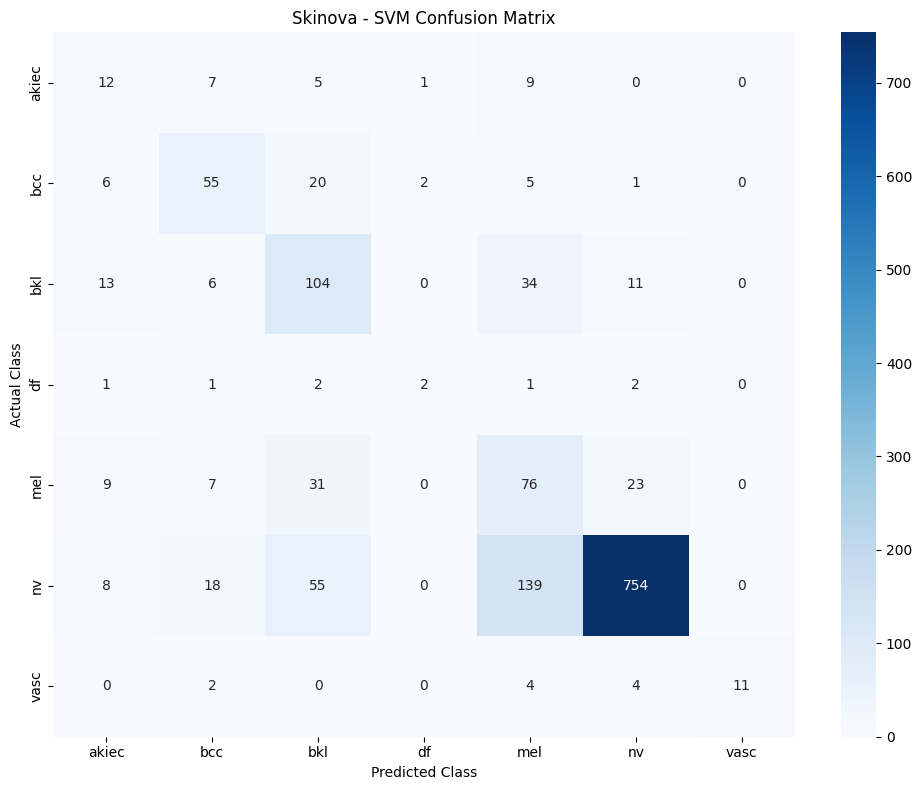

In [159]:

cm = confusion_matrix(
    y_svm["test"],
    y_pred_svm,
    labels=np.arange(len(CLASSES))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.title("Skinova - SVM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


In [160]:

SVM_OUTPUT_DIR = os.path.join(
    OUT_DIR,
    "svm"
)

os.makedirs(
    SVM_OUTPUT_DIR,
    exist_ok=True
)

# Save the trained SVM pipeline
joblib.dump(
    best_svm,
    os.path.join(SVM_OUTPUT_DIR, "svm_model.pkl")
)

# Save the EfficientNetB0 feature extractor
svm_feature_extractor.save(
    os.path.join(
        SVM_OUTPUT_DIR,
        "efficientnetb0_feature_extractor.keras"
    )
)

# Save model configuration
joblib.dump(
    {
        "classes": CLASSES,
        "best_C": best_c
    },
    os.path.join(SVM_OUTPUT_DIR, "svm_config.pkl")
)

print("SVM model saved successfully!")

print("\nSaved files:")

for filename in os.listdir(SVM_OUTPUT_DIR):
    print(filename)


SVM model saved successfully!

Saved files:
svm_config.pkl
svm_model.pkl
efficientnetb0_feature_extractor.keras


**ViT**


In [161]:
import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import vit_b_16, ViT_B_16_Weights

from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Reproducibility
VIT_SEED = 42

random.seed(VIT_SEED)
np.random.seed(VIT_SEED)
torch.manual_seed(VIT_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(VIT_SEED)

vit_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", vit_device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Use existing prepared data
assert "dfs" in globals(), "Run the existing data loading cell first."
assert "Y" in globals(), "Labels are missing."
assert "CLASSES" in globals(), "Classes are missing."

print("Classes:", CLASSES)

for split in ["train", "val", "test"]:
    print(
        split,
        "Images:", len(dfs[split]),
        "Labels:", len(Y[split])
    )

    assert len(dfs[split]) == len(Y[split])

Device: cuda
GPU: Tesla T4
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
train Images: 7145 Labels: 7145
val Images: 1429 Labels: 1429
test Images: 1441 Labels: 1441


In [162]:
VIT_IMAGE_SIZE = 224
VIT_BATCH_SIZE = 8
VIT_NUM_WORKERS = 2

# Training transformations
vit_train_transform = transforms.Compose([
    transforms.Resize((VIT_IMAGE_SIZE, VIT_IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and testing transformations
vit_eval_transform = transforms.Compose([
    transforms.Resize((VIT_IMAGE_SIZE, VIT_IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class ViTSkinovaDataset(Dataset):

    def __init__(self, dataframe, labels, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.labels = np.asarray(labels, dtype=np.int64)
        self.transform = transform

        assert len(self.dataframe) == len(self.labels)
        assert self.dataframe["image_path"].notna().all()

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        image_path = self.dataframe.loc[idx, "image_path"]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return image, label


# Create independent ViT datasets
vit_train_dataset = ViTSkinovaDataset(
    dfs["train"],
    Y["train"],
    vit_train_transform
)

vit_val_dataset = ViTSkinovaDataset(
    dfs["val"],
    Y["val"],
    vit_eval_transform
)

vit_test_dataset = ViTSkinovaDataset(
    dfs["test"],
    Y["test"],
    vit_eval_transform
)


# Create independent ViT DataLoaders
vit_train_loader = DataLoader(
    vit_train_dataset,
    batch_size=VIT_BATCH_SIZE,
    shuffle=True,
    num_workers=VIT_NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

vit_val_loader = DataLoader(
    vit_val_dataset,
    batch_size=VIT_BATCH_SIZE,
    shuffle=False,
    num_workers=VIT_NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

vit_test_loader = DataLoader(
    vit_test_dataset,
    batch_size=VIT_BATCH_SIZE,
    shuffle=False,
    num_workers=VIT_NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


# Check one batch
vit_images, vit_labels = next(iter(vit_train_loader))

print("Images shape:", vit_images.shape)
print("Labels shape:", vit_labels.shape)

print("Train batches:", len(vit_train_loader))
print("Validation batches:", len(vit_val_loader))
print("Test batches:", len(vit_test_loader))

Images shape: torch.Size([8, 3, 224, 224])
Labels shape: torch.Size([8])
Train batches: 894
Validation batches: 179
Test batches: 181


In [163]:
# Load pretrained Vision Transformer
vit_model = vit_b_16(
    weights=ViT_B_16_Weights.IMAGENET1K_V1
)

# Replace classification head
vit_model.heads.head = nn.Linear(
    vit_model.heads.head.in_features,
    len(CLASSES)
)

vit_model = vit_model.to(vit_device)

print("Pretrained ViT-B/16 loaded successfully!")
print("Number of classes:", len(CLASSES))

print("Model device:", next(vit_model.parameters()).device)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 205MB/s] 


Pretrained ViT-B/16 loaded successfully!
Number of classes: 7
Model device: cuda:0


In [164]:
# Calculate class weights from training data only
vit_class_counts = np.bincount(
    Y["train"],
    minlength=len(CLASSES)
)

vit_class_weights = (
    vit_class_counts.sum() /
    (len(CLASSES) * vit_class_counts)
) ** 0.5

vit_class_weights = torch.tensor(
    vit_class_weights,
    dtype=torch.float32
).to(vit_device)

# Weighted loss
vit_criterion = nn.CrossEntropyLoss(
    weight=vit_class_weights
)

# Optimizer
vit_optimizer = torch.optim.AdamW(
    vit_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

# Learning rate scheduler
vit_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    vit_optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

# Mixed precision
vit_amp_enabled = torch.cuda.is_available()

vit_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=vit_amp_enabled
)

print("Loss, optimizer and scheduler are ready!")
print("Class weights:", vit_class_weights)

Loss, optimizer and scheduler are ready!
Class weights: tensor([2.0453, 1.6885, 1.1439, 3.5945, 1.1198, 0.4626, 3.1790],
       device='cuda:0')


In [166]:
from contextlib import nullcontext

def vit_train_one_epoch():

    vit_model.train()

    total_loss = 0
    all_labels = []
    all_predictions = []

    for images, labels in vit_train_loader:

        images = images.to(vit_device)
        labels = labels.to(vit_device)

        vit_optimizer.zero_grad(set_to_none=True)

        amp_context = (
            torch.autocast(device_type="cuda")
            if vit_amp_enabled
            else nullcontext()
        )

        with amp_context:

            outputs = vit_model(images)

            loss = vit_criterion(
                outputs,
                labels
            )

        vit_scaler.scale(loss).backward()

        vit_scaler.step(vit_optimizer)
        vit_scaler.update()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    epoch_loss = total_loss / len(vit_train_loader)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1


def vit_evaluate(loader):

    vit_model.eval()

    total_loss = 0
    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(vit_device)
            labels = labels.to(vit_device)

            amp_context = (
                torch.autocast(device_type="cuda")
                if vit_amp_enabled
                else nullcontext()
            )

            with amp_context:

                outputs = vit_model(images)

                loss = vit_criterion(
                    outputs,
                    labels
                )

            total_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    epoch_loss = total_loss / len(loader)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1

In [167]:
VIT_EPOCHS = 10
VIT_PATIENCE = 4

vit_best_f1 = 0
vit_best_state = None
vit_patience_counter = 0

vit_history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "train_f1": [],
    "val_f1": []
}

for epoch in range(VIT_EPOCHS):

    train_loss, train_acc, train_f1 = vit_train_one_epoch()

    val_loss, val_acc, val_f1 = vit_evaluate(
        vit_val_loader
    )

    vit_scheduler.step(val_f1)

    vit_history["train_loss"].append(train_loss)
    vit_history["val_loss"].append(val_loss)

    vit_history["train_accuracy"].append(train_acc)
    vit_history["val_accuracy"].append(val_acc)

    vit_history["train_f1"].append(train_f1)
    vit_history["val_f1"].append(val_f1)

    print(f"\nEpoch {epoch + 1}/{VIT_EPOCHS}")

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f} | "
        f"Train Macro F1: {train_f1:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

    # Save best model using validation Macro F1
    if val_f1 > vit_best_f1:

        vit_best_f1 = val_f1

        vit_best_state = copy.deepcopy(
            vit_model.state_dict()
        )

        vit_patience_counter = 0

        print("Best ViT model updated!")

    else:

        vit_patience_counter += 1

    if vit_patience_counter >= VIT_PATIENCE:

        print("Early stopping triggered!")
        break


# Restore best model
if vit_best_state is None:
    raise RuntimeError("ViT training did not produce a valid model.")

vit_model.load_state_dict(vit_best_state)

print("\nViT Training Completed!")
print("Best Validation Macro F1:", vit_best_f1)


Epoch 1/10
Train Loss: 0.8969 | Train Accuracy: 0.7484 | Train Macro F1: 0.5514
Val Loss: 0.6111 | Val Accuracy: 0.7838 | Val Macro F1: 0.6281
Best ViT model updated!

Epoch 2/10
Train Loss: 0.5838 | Train Accuracy: 0.8242 | Train Macro F1: 0.7200
Val Loss: 0.5315 | Val Accuracy: 0.8146 | Val Macro F1: 0.7145
Best ViT model updated!

Epoch 3/10
Train Loss: 0.4684 | Train Accuracy: 0.8525 | Train Macro F1: 0.7798
Val Loss: 0.5868 | Val Accuracy: 0.7922 | Val Macro F1: 0.6879

Epoch 4/10
Train Loss: 0.3404 | Train Accuracy: 0.8878 | Train Macro F1: 0.8489
Val Loss: 0.4971 | Val Accuracy: 0.8293 | Val Macro F1: 0.7450
Best ViT model updated!

Epoch 5/10
Train Loss: 0.2759 | Train Accuracy: 0.9057 | Train Macro F1: 0.8791
Val Loss: 0.5786 | Val Accuracy: 0.8202 | Val Macro F1: 0.6674

Epoch 6/10
Train Loss: 0.2346 | Train Accuracy: 0.9209 | Train Macro F1: 0.8955
Val Loss: 0.5268 | Val Accuracy: 0.8251 | Val Macro F1: 0.7375

Epoch 7/10
Train Loss: 0.1695 | Train Accuracy: 0.9430 | Train 

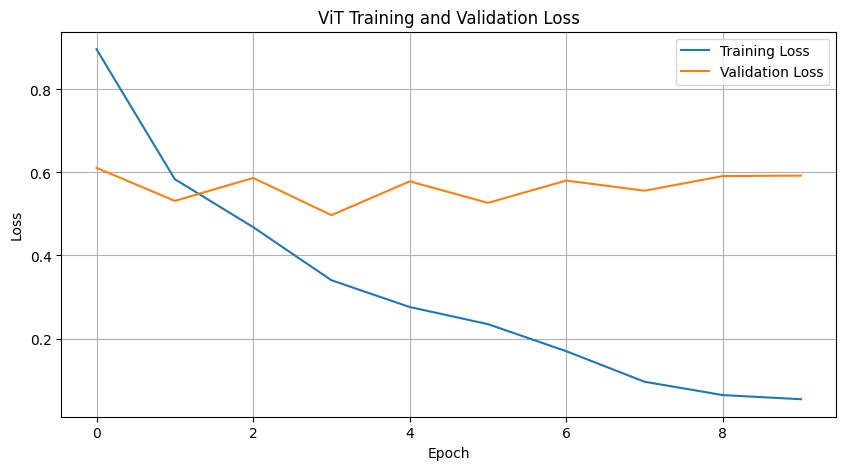

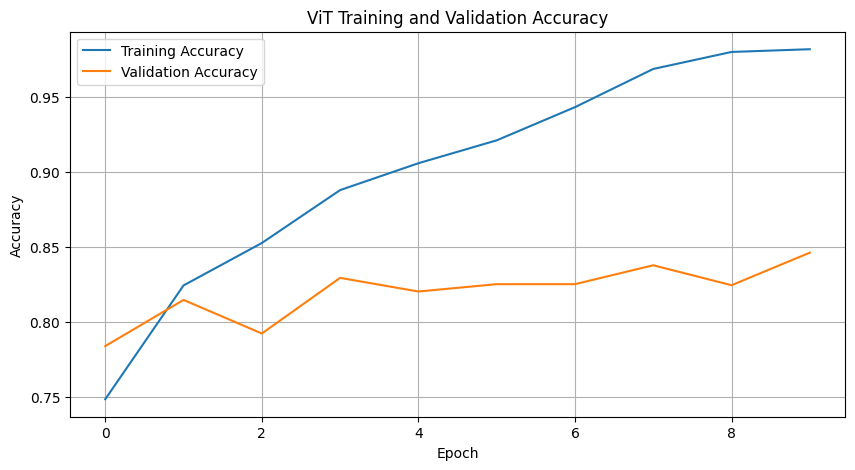

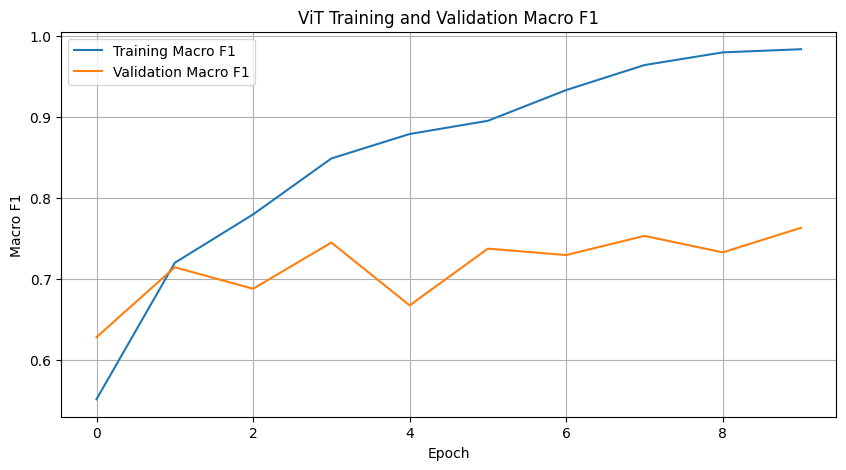

In [168]:
plt.figure(figsize=(10, 5))

plt.plot(
    vit_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    vit_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ViT Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    vit_history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    vit_history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ViT Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    vit_history["train_f1"],
    label="Training Macro F1"
)

plt.plot(
    vit_history["val_f1"],
    label="Validation Macro F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("ViT Training and Validation Macro F1")

plt.legend()
plt.grid(True)
plt.show()

In [169]:
vit_test_loss, vit_test_acc, vit_test_f1 = vit_evaluate(
    vit_test_loader
)

vit_model.eval()

vit_y_true = []
vit_y_pred = []

with torch.no_grad():

    for images, labels in vit_test_loader:

        images = images.to(vit_device)

        outputs = vit_model(images)

        predictions = outputs.argmax(dim=1)

        vit_y_true.extend(labels.numpy())
        vit_y_pred.extend(predictions.cpu().numpy())


vit_accuracy = accuracy_score(
    vit_y_true,
    vit_y_pred
)

vit_precision = precision_score(
    vit_y_true,
    vit_y_pred,
    average="macro",
    zero_division=0
)

vit_recall = recall_score(
    vit_y_true,
    vit_y_pred,
    average="macro",
    zero_division=0
)

vit_macro_f1 = f1_score(
    vit_y_true,
    vit_y_pred,
    average="macro",
    zero_division=0
)

vit_balanced_acc = balanced_accuracy_score(
    vit_y_true,
    vit_y_pred
)

print("========== ViT TEST RESULTS ==========")

print(f"Test Accuracy: {vit_accuracy:.4f}")
print(f"Macro Precision: {vit_precision:.4f}")
print(f"Macro Recall: {vit_recall:.4f}")
print(f"Macro F1-score: {vit_macro_f1:.4f}")
print(f"Balanced Accuracy: {vit_balanced_acc:.4f}")

========== ViT TEST RESULTS ==========
Test Accuracy: 0.8265
Macro Precision: 0.7060
Macro Recall: 0.6554
Macro F1-score: 0.6756
Balanced Accuracy: 0.6554


========== ViT CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

       akiec     0.4167    0.4412    0.4286        34
         bcc     0.7895    0.6742    0.7273        89
         bkl     0.6429    0.6964    0.6686       168
          df     0.6667    0.4444    0.5333         9
         mel     0.4909    0.5548    0.5209       146
          nv     0.9353    0.9199    0.9275       974
        vasc     1.0000    0.8571    0.9231        21

    accuracy                         0.8265      1441
   macro avg     0.7060    0.6554    0.6756      1441
weighted avg     0.8342    0.8265    0.8295      1441



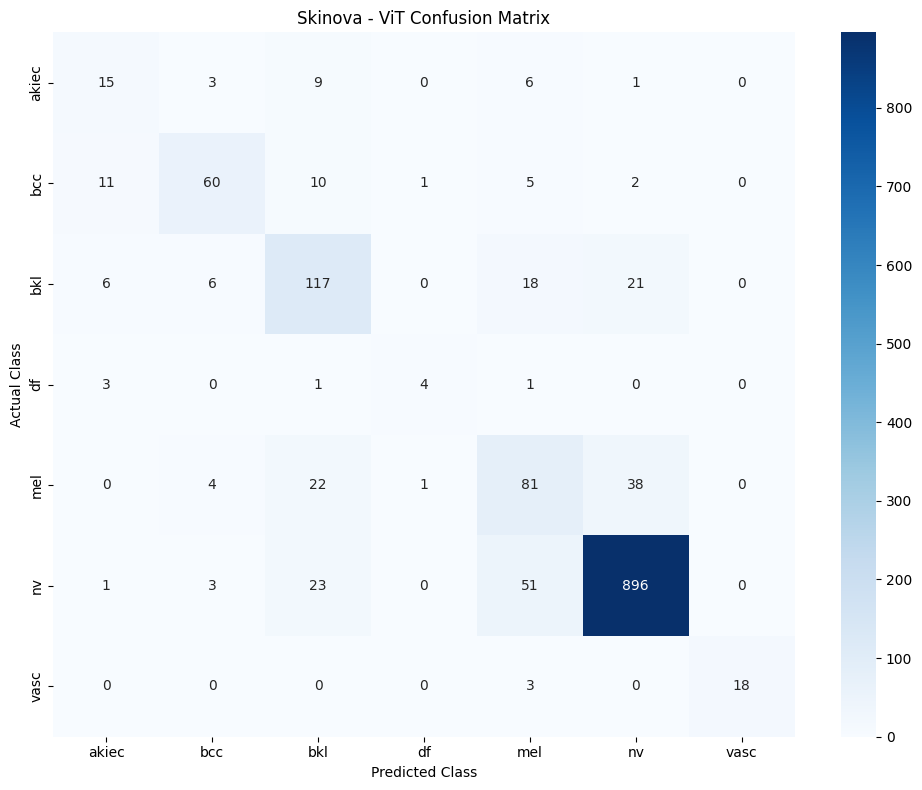

In [170]:
print("========== ViT CLASSIFICATION REPORT ==========")

print(
    classification_report(
        vit_y_true,
        vit_y_pred,
        labels=np.arange(len(CLASSES)),
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)


vit_cm = confusion_matrix(
    vit_y_true,
    vit_y_pred,
    labels=np.arange(len(CLASSES))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    vit_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.title("Skinova - ViT Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [171]:
VIT_OUTPUT_DIR = "/kaggle/working/skinova_outputs/vit"

os.makedirs(
    VIT_OUTPUT_DIR,
    exist_ok=True
)

# Save best model
torch.save(
    vit_model.state_dict(),
    os.path.join(VIT_OUTPUT_DIR, "vit_best_model.pth")
)

# Save training history
pd.DataFrame(vit_history).to_csv(
    os.path.join(VIT_OUTPUT_DIR, "vit_training_history.csv"),
    index=False
)

# Save test predictions
pd.DataFrame({
    "true_label": vit_y_true,
    "predicted_label": vit_y_pred
}).to_csv(
    os.path.join(VIT_OUTPUT_DIR, "vit_test_predictions.csv"),
    index=False
)

# Save metrics
vit_results = pd.DataFrame([{
    "Model": "ViT-B/16",
    "Accuracy": vit_accuracy,
    "Macro Precision": vit_precision,
    "Macro Recall": vit_recall,
    "Macro F1": vit_macro_f1,
    "Balanced Accuracy": vit_balanced_acc,
    "Best Validation Macro F1": vit_best_f1
}])

vit_results.to_csv(
    os.path.join(VIT_OUTPUT_DIR, "vit_test_results.csv"),
    index=False
)

print("ViT model and results saved successfully!")

print("\nSaved files:")

for filename in os.listdir(VIT_OUTPUT_DIR):
    print(filename)

ViT model and results saved successfully!

Saved files:
vit_test_predictions.csv
vit_test_results.csv
vit_training_history.csv
vit_best_model.pth
